# ChemBERTa embeddings

- This notebook generates embeddings across several datasets using the **ChemBERTa** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [1]:
import pandas as pd
import numpy as np
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm
import sklearn
from sklearn.metrics.pairwise import cosine_similarity

/home/blake/miniconda3/envs/chemberta2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## File paths

Edit the following paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''

# Model set-up

In [2]:
model_name = "DeepChem/ChemBERTa-77M-MLM"

In [3]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
model     = AutoModel.from_pretrained(model_name)

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 9282.15it/s]
[transformers] RobertaModel LOAD REPORT from: DeepChem/ChemBERTa-77M-MLM
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [4]:
print(f"Total parameters: {model.num_parameters():,}")
print(
    f"Trainable parameters: "
    f"{model.num_parameters(only_trainable=True):,}"
)

Total parameters: 3,427,440
Trainable parameters: 3,427,440


In [4]:
def embed(tokenizer, smiles):
    inputs = tokenizer(
        smiles,
        padding=True,
        truncation=True,
        return_tensors="pt"
    )

    with torch.no_grad():
        outputs = model(**inputs)

    # CLS-style molecule embedding
    embeddings = outputs.last_hidden_state[:, 0, :]
    return embeddings


def embed_batched(tokenizer, smiles, batch_size=256):
    all_embeddings = []

    for i in range(0, len(smiles), batch_size):
        batch = smiles[i:i + batch_size]

        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            return_tensors="pt"
        )

        with torch.no_grad():
            outputs = model(**inputs)

        # CLS-style molecule embedding
        embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(embeddings)

    return torch.cat(all_embeddings, dim=0)

# MCES

In [ ]:
distances = np.load(MCES_PATH)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

In [ ]:
embeddings = embed_batched(tokenizer, list(smiles))
np.save('MCES/ChemBERTa MCES embeddings.npy', embeddings)

In [ ]:
# Save cosine similarities in a flattened row-major, upper triangle format.

X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/ChemBERTa MCES pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

100%|██████████| 64/64 [01:49<00:00,  1.71s/it]


Expected length: 2012094766
Written length: 2012094766


In [ ]:
# Save indices in a flattened row-major, upper triangle format.

n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/ChemBERTa MCES pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

100%|██████████| 63436/63436 [00:28<00:00, 2194.97it/s] 

Expected: 2012094766
Written: 2012094766


# MCES figure example

Cosine similarity: [[0.9542857]]


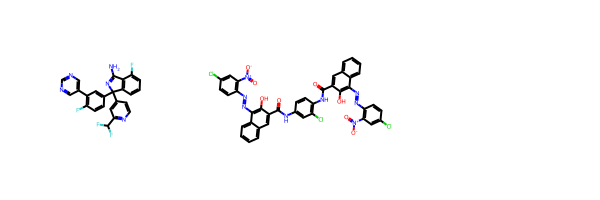

In [13]:
close_pair_a = "C1=CC2=C(C(=C1)F)C(=NC2(C3=CC(=C(C=C3)F)C4=CN=CN=C4)C5=CC(=NC=C5)C(F)F)N"
close_pair_b = "C1=CC=C2C(=C1)C=C(C(=C2N=NC3=C(C=C(C=C3)Cl)[N+](=O)[O-])O)C(=O)NC4=CC(=C(C=C4)NC(=O)C5=CC6=CC=CC=C6C(=C5O)N=NC7=C(C=C(C=C7)Cl)[N+](=O)[O-])Cl"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

embeddings = embed(tokenizer=tokenizer, smiles=[close_pair_a, close_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

Cosine similarity: [[0.08227235]]


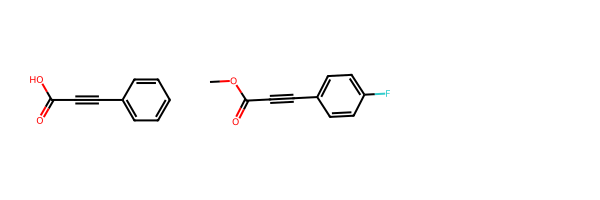

In [14]:
distant_pair_a = "C1=CC=C(C=C1)C#CC(=O)O"
distant_pair_b = "COC(=O)C#CC1=CC=C(C=C1)F"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

embeddings = embed(tokenizer=tokenizer, smiles=[distant_pair_a, distant_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

# Biogen embeddings

In [ ]:
biogen = pd.read_csv(BIOGEN_PATH)
smiles = biogen['SMILES'].tolist()

In [ ]:
embeddings = embed(tokenizer, smiles)
np.save('Biogen/ChemBERTa Biogen embeddings.npy', embeddings)

# ZINC embeddings

In [ ]:
# ZINC file contains randomly sampled molecules. 
data   = pd.read_csv(ZINC30K_PATH)[:30000]
smiles = data['SMILES'].tolist()

In [ ]:
embeddings = embed_batched(tokenizer, list(smiles))
np.save('ZINC/ChemBERTa ZINC30K embeddings.npy', embeddings)